# CEOS MIM Database from Python: `ceos-capabilities`

A small client for the CEOS MIM Database, the data behind the [EO Capabilities Explorer](https://ceos-capabilities.org).

It reads the database in one of two ways, with the same calls and the same answers:

- **Offline (the default).** A snapshot of the database ships inside the package. No network, no rate limit, the same result on every machine. Suited to pipelines and containers.
- **Live.** Turn on `mode="api"` to call the public API for the data it serves now. That is the API's latest extract of the database, which can lag the CEOS Database site until the next extract.

**Early release.** A proof of concept from Phase 1 of the CEOS MIM+ pilot; the interface may change before 1.0.

In [1]:
%pip install -q "ceos-capabilities[pandas]==0.1.0" matplotlib

## 1. Open the database (offline)

In [2]:
from ceos_capabilities import Client

db = Client()          # offline: no network call is made
print(db.edition)
print(db.citation())

CEOS MIM Database, edition e574f0c2, data as of 2026-10-23 (snapshot: snapshot.json.gz)
CEOS MIM Database, https://database.eohandbook.com. Edition e574f0c2, data as of 2026-10-23. Licensed under CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/).


Every client can say which data it is reading and how to cite it. The data is CC BY 4.0.

## 2. Missions as a table

In [3]:
missions = db.missions().to_pandas()
print(len(missions), "missions")
missions["status"].value_counts().head(8)

1200 missions


status
Mission complete          530
Operational (nominal)     242
Operational (extended)    121
Cancelled                  95
Approved                   83
Planned                    75
N/A                        35
Commissioning              11
Name: count, dtype: int64

## 3. One mission, by id, by name or by an alternate name

In [4]:
m = db.mission("S1A")          # an alternate name; "sentinel-1-a" and 575 give the same record
{k: m[k] for k in ("mission_id", "mission_acronym", "full_name", "launch_date", "eol_date", "status", "orbit_type")}

{'mission_id': 575,
 'mission_acronym': 'Sentinel-1 A',
 'full_name': 'Sentinel-1 A',
 'launch_date': '2014-04-03',
 'eol_date': '2026-06-29',
 'status': 'Mission complete',
 'orbit_type': 'Sun-synchronous'}

In [5]:
db.mission_instruments("sentinel-1-a")["instruments"]

[{'instrument_id': 939,
  'instrument_acronym': 'C-Band SAR',
  'full_name': 'C-Band Synthetic Aperture Radar',
  'types': ['Imaging microwave radars']}]

## 4. A lineage: the Landsat series as a timeline

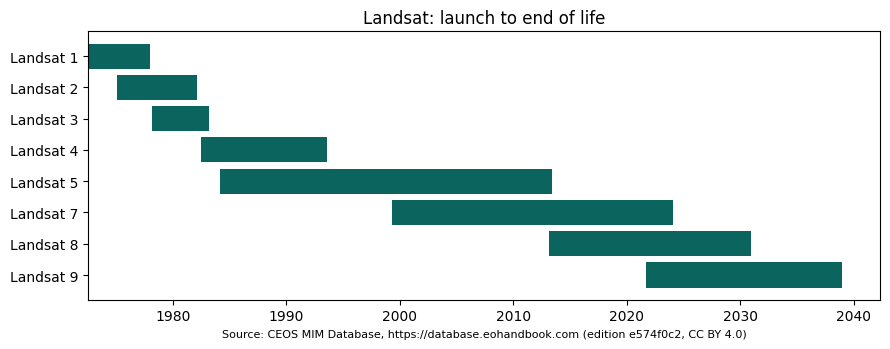

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

landsat = db.series_detail("landsat")
members = pd.DataFrame(landsat["members"])
members["launch"] = pd.to_datetime(members["launch_date"], errors="coerce")
members["end"] = pd.to_datetime(members["eol_date"], errors="coerce").fillna(pd.Timestamp.today())
members = members.dropna(subset=["launch"]).sort_values("launch")

fig, ax = plt.subplots(figsize=(9, 3.6))
start = mdates.date2num(members["launch"])
ax.barh(members["mission_acronym"], mdates.date2num(members["end"]) - start, left=start, color="#0b655e")
ax.xaxis_date()
ax.invert_yaxis()
ax.set_title(f"{landsat['name_full']}: launch to end of life")
ax.set_xlabel(f"Source: {db.licence['attribution']} (edition {db.edition.edition}, {db.licence['name']})", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Extended parameters: the imaging modes of a SAR instrument

In [7]:
palsar2 = db.sar_parameters(1589)      # PALSAR-2 on ALOS-2
print(palsar2["instrument_name_full"], "|", palsar2["source"])
pd.DataFrame(palsar2["imaging_modes"])[["mode_name", "azimuth_resolution_m", "bandwidth_mhz",
                                        "incidence_angle_min_deg", "incidence_angle_max_deg"]].head(8)

Phased Array type L-band Synthetic Aperture Radar-2 | 2026 Extended Parameters Survey (JAXA, 2026-07-16)


,mode_name,azimuth_resolution_m,bandwidth_mhz,incidence_angle_min_deg,incidence_angle_max_deg
0,ScanSAR (Normal - 14 MHz Bandwidth),100.0,14.0,8.0,70.0
1,ScanSAR (Normal - 28 MHz Bandwidth),100.0,28.0,8.0,70.0
2,ScanSAR (Wide Beam),60.0,14.0,8.0,70.0
3,Spotlight,1.0,84.0,8.0,70.0
4,Stripmap Fine - FullPol,10.0,28.0,23.7,23.7
5,Stripmap Fine - Single/Dual/Compact Pol,10.0,28.0,8.0,70.0
6,Stripmap High Sensitive - Full Pol,6.0,42.0,20.0,40.0
7,Stripmap High Sensitive - Single/Dual/Compact Pol,6.0,42.0,8.0,70.0


## 6. The same calls against the live API

Nothing else changes. This cell needs the network; the ones above did not.

In [8]:
live = Client(mode="api")
print(live.edition)
print("same record offline and live:", live.mission("sentinel-1-a") == db.mission("sentinel-1-a"))
print("same edition:", live.edition.edition == db.edition.edition)

CEOS MIM Database, edition e574f0c2, data as of 2026-10-23 (api: https://ceos-capabilities.org/api)
same record offline and live: True
same edition: True


## What this shows

- One import and one line to get the whole database as tables, with no key and no network.
- The same code runs against the live API by changing one argument.
- Results carry their edition, date and licence, so anything built on them can be cited.

What it does not do yet: refresh to a newer published edition (the mechanism is built, but no editions are published), the analysis endpoints offline, and anything that writes.